<a href="https://colab.research.google.com/github/yimarbriceon/ingenieria-conocimiento-uncp/blob/master/Parcial-Primera-Unidad/Actividad1_VN_parcial_1era_unidad.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **# Pipeline de Machine Learning Clásico: Predicción del Consumo de Cannabis a partir de Rasgos de Personalidad**

## SECCIÓN A — Presentación

| | |
|---|---|
| **Curso** | Ingeniería del Conocimiento (ISO56B) |
| **Universidad** | UNCP — Facultad de Ingeniería de Sistemas |
| **Semestre** | 2026-II |
| **Fecha** | 17 de octubre de 2026 |
| **Docente** | Msc. Jaime Antonio Huaytalla Pariona |

### **Integrantes**
| N° | Nombre | Código |
|---|---|---|
| 1 | Huaynalaya Alonzo Frank Elvis | [código] |
| 2 | Quintanilla Condor Juan Josue | [código] |
| 3 | Gomez Muñoz David Pedro | [código] |
| 4 | Briceño Alaya Yimar Jesús | [código] |

### **Dataset elegido**
- **Nombre:** Drug Consumption (Quantified)
- **Fuente:** UCI Machine Learning Repository — https://archive.ics.uci.edu/dataset/373/drug+consumption+quantified
- **Autores originales:** Fehrman, E., Egan, V., Mirkes, E. (2016).

### **Justificación de la elección**
1. Cumple todos los requisitos: es tabular, de clasificación, con datos **reales** (1885 encuestados), más de 500 registros, más de 5 features y al menos 2 clases.
2. Es un problema con **relevancia social y de salud pública**: identificar perfiles de riesgo de consumo de sustancias.
3. Tiene variables de distinta naturaleza (personalidad, demográficas, nominales cuantificadas), lo que permite justificar decisiones de preprocesamiento.
4. No es un dataset visto en clase ni en los laboratorios.

### **Descripción del problema**
El dataset contiene 1885 personas con 12 atributos: 7 rasgos psicológicos (Neuroticismo, Extraversión, Apertura, Amabilidad, Responsabilidad, Impulsividad y Búsqueda de Sensaciones) y 5 atributos demográficos (edad, género, educación, país y etnia), todos ya cuantificados numéricamente. Cada persona reportó su frecuencia de consumo de 18 sustancias en 7 niveles (CL0 a CL6). Nuestro problema es de **clasificación binaria**: predecir si una persona es **consumidora reciente de cannabis** (último año o menos, clase 1) o **no consumidora reciente** (clase 0), usando únicamente sus rasgos de personalidad y datos demográficos. Evaluaremos varios modelos de ML clásico, elegiremos el mejor, optimizaremos sus hiperparámetros y lo serializaremos con `joblib`.

## SECCIÓN B — Carga y Análisis Exploratorio de Datos (EDA)

Cargamos el dataset directamente desde el repositorio UCI con la librería `ucimlrepo` (descarga desde URL pública, sin archivos locales), definimos la variable objetivo binaria y exploramos la estructura de los datos.

In [ ]:
# ============================================================
# CONFIGURACIÓN INICIAL
# ============================================================
# Instalar la librería para descargar datasets de UCI (solo la primera vez)
!pip install -q ucimlrepo xgboost catboost

# --- Librerías principales ---
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings
warnings.filterwarnings('ignore')

# --- Scikit-learn ---
from sklearn.base import clone
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     cross_val_score, GridSearchCV)
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, GradientBoostingClassifier,
                              StackingClassifier)
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve)

# --- Reproducibilidad ---
SEED = 42
np.random.seed(SEED)

# --- Estilo visual ---
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 11
sns.set_style('whitegrid')

print("✅ Librerías cargadas correctamente.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 6.5 MB/s eta 0:00:00
✅ Librerías cargadas correctamente.


### B.1 Carga del dataset y definición de la variable objetivo

El dataset original trae 18 columnas objetivo (una por droga) con niveles `CL0`–`CL6`:

| Nivel | Significado |
|---|---|
| CL0 | Nunca la ha consumido |
| CL1 | Consumió hace más de 10 años |
| CL2 | Consumió en la última década |
| CL3 | Consumió en el último año |
| CL4 | Consumió en el último mes |
| CL5 | Consumió en la última semana |
| CL6 | Consumió en el último día |

Construimos una **variable binaria**: `0` si el nivel es CL0–CL2 (no consumidor reciente) y `1` si es CL3–CL6 (consumidor reciente).

In [ ]:
# ============================================================
# B.1 CARGA DEL DATASET
# ============================================================
from ucimlrepo import fetch_ucirepo

# Descarga directa desde el repositorio UCI (id=373)
drug = fetch_ucirepo(id=373)
X_raw = drug.data.features.copy()   # 12 atributos (ya cuantificados)
y_raw = drug.data.targets.copy()    # 18 drogas (niveles CL0-CL6)

# Estandarizamos nombres de columnas (minúsculas) y corregimos el typo del original
X_raw.columns = X_raw.columns.str.lower().str.strip()
y_raw.columns = y_raw.columns.str.lower().str.strip()
X_raw = X_raw.rename(columns={'impuslive': 'impulsive'})

# --- Droga elegida como objetivo (puedes cambiarla por otra de la lista) ---
DROGA = 'cannabis'
print("Drogas disponibles:", list(y_raw.columns))
assert DROGA in y_raw.columns, "La droga elegida no existe en el dataset"

# Extraemos el número del nivel: 'CL3' -> 3
nivel = y_raw[DROGA].astype(str).str.extract(r'(\d)')[0].astype(int)

# Nombres legibles de los niveles (para gráficos)
NIVELES = {0: 'Nunca', 1: '>10 años', 2: 'Última década', 3: 'Último año',
           4: 'Último mes', 5: 'Última semana', 6: 'Último día'}

# DataFrame de trabajo: features + nivel original + objetivo binario
df = X_raw.copy()
df['nivel_consumo'] = nivel
df['objetivo'] = (nivel >= 3).astype(int)    # 1 = consumidor reciente
df['clase'] = df['objetivo'].map({0: 'No consumidor reciente', 1: 'Consumidor reciente'})

print(f"\n✅ Dataset cargado. Droga objetivo: {DROGA.upper()}")
print(f"   Features: {list(X_raw.columns)}")

Drogas disponibles: ['alcohol', 'amphet', 'amyl', 'benzos', 'caff', 'cannabis', 'choc', 'coke', 'crack', 'ecstasy', 'heroin', 'ketamine', 'legalh', 'lsd', 'meth', 'mushrooms', 'nicotine', 'semer', 'vsa']

✅ Dataset cargado. Droga objetivo: CANNABIS
   Features: ['age', 'gender', 'education', 'country', 'ethnicity', 'nscore', 'escore', 'oscore', 'ascore', 'cscore', 'impulsive', 'ss']


### B.2 Primeras filas, shape, tipos de datos y valores nulos

Revisamos la estructura básica: dimensiones, tipo de cada columna, presencia de valores nulos y filas duplicadas.

In [ ]:
# ============================================================
# B.2 ESTRUCTURA BÁSICA DEL DATASET
# ============================================================
print("=" * 60)
print("INFORMACIÓN GENERAL")
print("=" * 60)
print(f"Shape (filas, columnas): {df.shape}")
print(f"Registros:               {df.shape[0]}")
print(f"Features originales:     {X_raw.shape[1]}")

print("\n--- Tipos de datos ---")
print(df.dtypes)

print("\n--- Valores nulos por columna ---")
print(df.isnull().sum())
print(f"\nTotal de nulos:      {df.isnull().sum().sum()}")
print(f"Filas duplicadas:    {df.duplicated().sum()}")

print("\n--- Primeras 5 filas ---")
df.head()

INFORMACIÓN GENERAL
Shape (filas, columnas): (1885, 15)
Registros:               1885
Features originales:     12

--- Tipos de datos ---
age              float64
gender           float64
education        float64
country          float64
ethnicity        float64
nscore           float64
escore           float64
oscore           float64
ascore           float64
cscore           float64
impulsive        float64
ss               float64
nivel_consumo      int64
objetivo           int64
clase             object
dtype: object

--- Valores nulos por columna ---
age              0
gender           0
education        0
country          0
ethnicity        0
nscore           0
escore           0
oscore           0
ascore           0
cscore           0
impulsive        0
ss               0
nivel_consumo    0
objetivo         0
clase            0
dtype: int64

Total de nulos:      0
Filas duplicadas:    0

--- Primeras 5 filas ---


,age,gender,education,country,ethnicity,nscore,escore,oscore,ascore,cscore,impulsive,ss,nivel_consumo,objetivo,clase
0,0.49788,0.48246,-0.05921,0.96082,0.12600,0.31287,-0.57545,-0.58331,-0.91699,-0.00665,-0.21712,-1.18084,0,0,No consumidor reciente
1,-0.07854,-0.48246,1.98437,0.96082,-0.31685,-0.67825,1.93886,1.43533,0.76096,-0.14277,-0.71126,-0.21575,4,1,Consumidor reciente
2,0.49788,-0.48246,-0.05921,0.96082,-0.31685,-0.46725,0.80523,-0.84732,-1.62090,-1.01450,-1.37983,0.40148,3,1,Consumidor reciente
3,-0.95197,0.48246,1.16365,0.96082,-0.31685,-0.14882,-0.80615,-0.01928,0.59042,0.58489,-1.37983,-1.18084,2,0,No consumidor reciente
4,0.49788,0.48246,1.98437,0.96082,-0.31685,0.73545,-1.63340,-0.45174,-0.30172,1.30612,-0.21712,-0.21575,3,1,Consumidor reciente


### B.3 Distribución de la variable objetivo

Visualizamos cuántas personas son consumidoras recientes vs no consumidoras. Esto determina si el problema está **balanceado** y qué métricas conviene priorizar (accuracy vs F1).

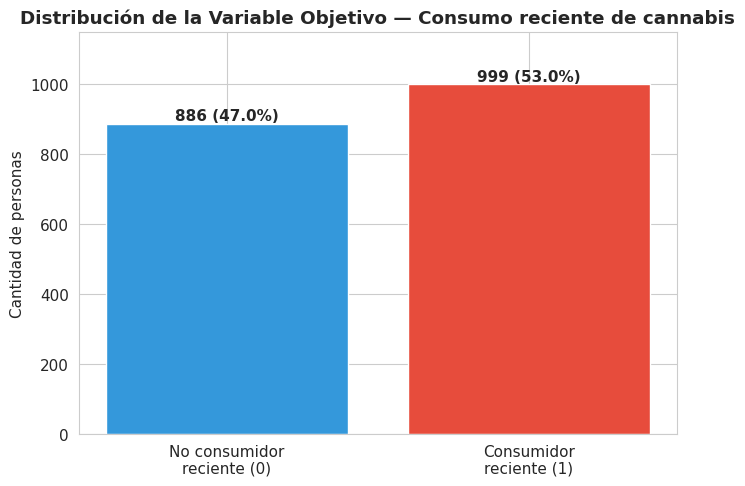

Ratio de balance (clase minoritaria / mayoritaria): 0.89


In [ ]:
# ============================================================
# B.3 DISTRIBUCIÓN DE LA VARIABLE OBJETIVO
# ============================================================
conteo = df['objetivo'].value_counts().sort_index()
porcentaje = df['objetivo'].value_counts(normalize=True).sort_index() * 100

fig, ax = plt.subplots(figsize=(7, 5))
colores = ['#3498db', '#e74c3c']
barras = ax.bar(['No consumidor\nreciente (0)', 'Consumidor\nreciente (1)'],
                conteo.values, color=colores, edgecolor='white')
for barra, c, p in zip(barras, conteo.values, porcentaje.values):
    ax.text(barra.get_x() + barra.get_width()/2, barra.get_height() + 10,
            f'{c} ({p:.1f}%)', ha='center', fontweight='bold')
ax.set_title(f'Distribución de la Variable Objetivo — Consumo reciente de {DROGA}',
             fontweight='bold')
ax.set_ylabel('Cantidad de personas')
ax.set_ylim(0, conteo.max() * 1.15)
plt.tight_layout()
plt.show()

print(f"Ratio de balance (clase minoritaria / mayoritaria): {conteo.min()/conteo.max():.2f}")

### B.4 Estadísticas descriptivas

Resumen estadístico (media, desviación, mínimo, cuartiles, máximo) de las variables numéricas. Como los atributos están **cuantificados** (transformados por los autores a escala numérica), esperamos valores centrados cerca de 0.

In [ ]:
# ============================================================
# B.4 ESTADÍSTICAS DESCRIPTIVAS
# ============================================================
print("Estadísticas descriptivas de las variables numéricas:\n")
display(X_raw.describe().T.round(3))

print("\nNúmero de valores únicos por variable (detecta variables nominales/ordinales cuantificadas):")
print(X_raw.nunique().sort_values())

Estadísticas descriptivas de las variables numéricas:



,count,mean,std,min,25%,50%,75%,max
age,1885.0,0.035,0.878,-0.952,-0.952,-0.079,0.498,2.592
gender,1885.0,-0.000,0.483,-0.482,-0.482,-0.482,0.482,0.482
education,1885.0,-0.004,0.950,-2.436,-0.611,-0.059,0.455,1.984
country,1885.0,0.356,0.700,-0.570,-0.570,0.961,0.961,0.961
ethnicity,1885.0,-0.310,0.166,-1.107,-0.317,-0.317,-0.317,1.907
nscore,1885.0,0.000,0.998,-3.464,-0.678,0.043,0.630,3.274
escore,1885.0,-0.000,0.997,-3.274,-0.695,0.003,0.638,3.274
oscore,1885.0,-0.001,0.996,-3.274,-0.717,-0.019,0.723,2.902
ascore,1885.0,-0.000,0.997,-3.464,-0.606,-0.017,0.761,3.464
cscore,1885.0,-0.000,0.998,-3.464,-0.653,-0.007,0.585,3.464



Número de valores únicos por variable (detecta variables nominales/ordinales cuantificadas):
gender        2
age           6
country       7
ethnicity     7
education     9
impulsive    10
ss           11
oscore       35
cscore       41
ascore       41
escore       42
nscore       49
dtype: int64


### B.5 Visualizaciones adicionales

Presentamos 5 visualizaciones:
1. Distribución de los 7 niveles originales de consumo
2. Histogramas de rasgos de personalidad por clase
3. Boxplots de rasgos de personalidad por clase
4. Proporción de consumidores recientes por grupo de edad
5. Mapa de correlación

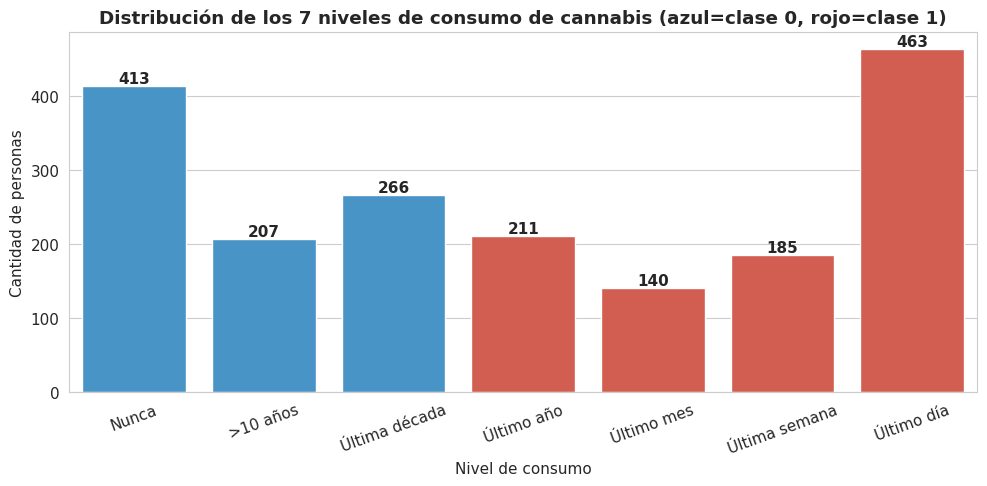

In [ ]:
# ============================================================
# B.5.1 DISTRIBUCIÓN DE LOS 7 NIVELES DE CONSUMO ORIGINALES
# ============================================================
fig, ax = plt.subplots(figsize=(10, 5))
orden = list(range(7))
colores_niv = ['#3498db']*3 + ['#e74c3c']*4   # azul = no reciente, rojo = reciente
sns.countplot(x=df['nivel_consumo'], order=orden, palette=colores_niv, ax=ax)
ax.set_xticklabels([NIVELES[i] for i in orden], rotation=20)
ax.set_xlabel('Nivel de consumo')
ax.set_ylabel('Cantidad de personas')
ax.set_title(f'Distribución de los 7 niveles de consumo de {DROGA} (azul=clase 0, rojo=clase 1)',
             fontweight='bold')
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width()/2, p.get_height()),
                ha='center', va='bottom', fontweight='bold')
plt.tight_layout()
plt.show()

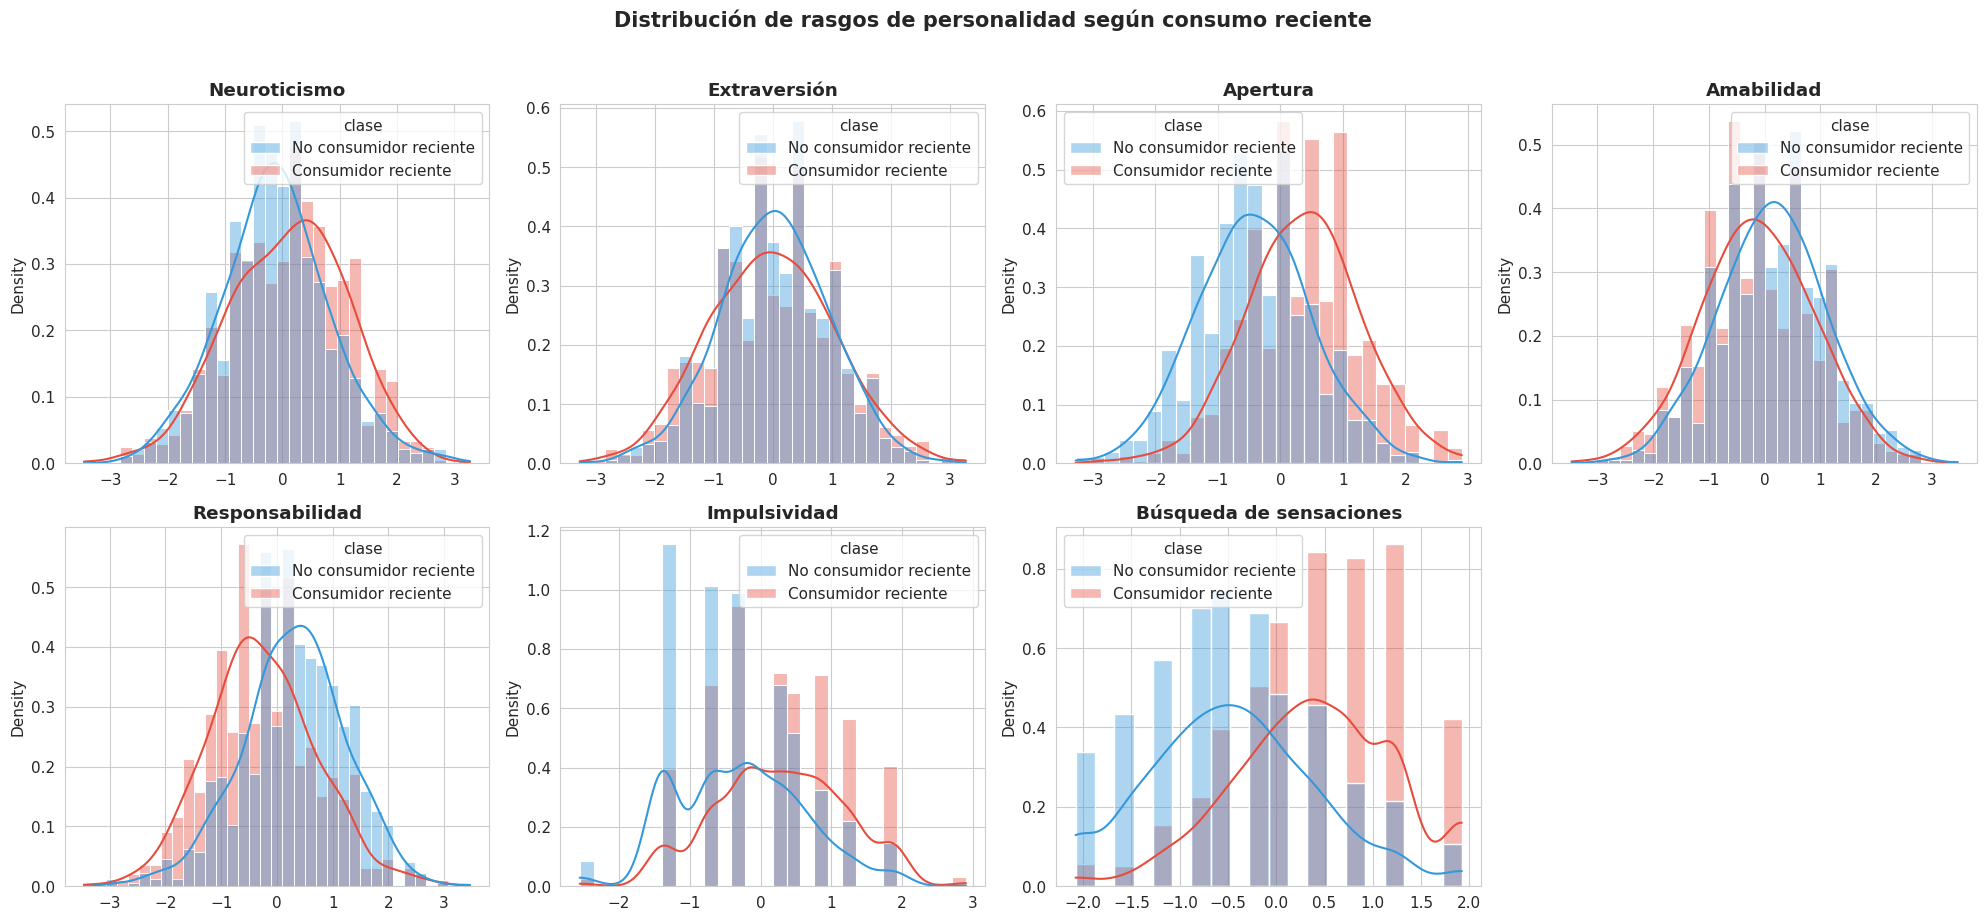

In [ ]:
# ============================================================
# B.5.2 HISTOGRAMAS DE PERSONALIDAD POR CLASE
# ============================================================
PERSONALIDAD = ['nscore', 'escore', 'oscore', 'ascore', 'cscore', 'impulsive', 'ss']
NOMBRES_PERS = {'nscore': 'Neuroticismo', 'escore': 'Extraversión', 'oscore': 'Apertura',
                'ascore': 'Amabilidad', 'cscore': 'Responsabilidad',
                'impulsive': 'Impulsividad', 'ss': 'Búsqueda de sensaciones'}
paleta = {'No consumidor reciente': '#3498db', 'Consumidor reciente': '#e74c3c'}

fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, col in zip(axes.flat, PERSONALIDAD):
    sns.histplot(data=df, x=col, hue='clase', kde=True, stat='density',
                 common_norm=False, palette=paleta, alpha=0.4, ax=ax)
    ax.set_title(NOMBRES_PERS[col], fontweight='bold')
    ax.set_xlabel('')
axes.flat[-1].axis('off')   # ocultamos el subplot sobrante
plt.suptitle('Distribución de rasgos de personalidad según consumo reciente',
             fontweight='bold', fontsize=15, y=1.02)
plt.tight_layout()
plt.show()

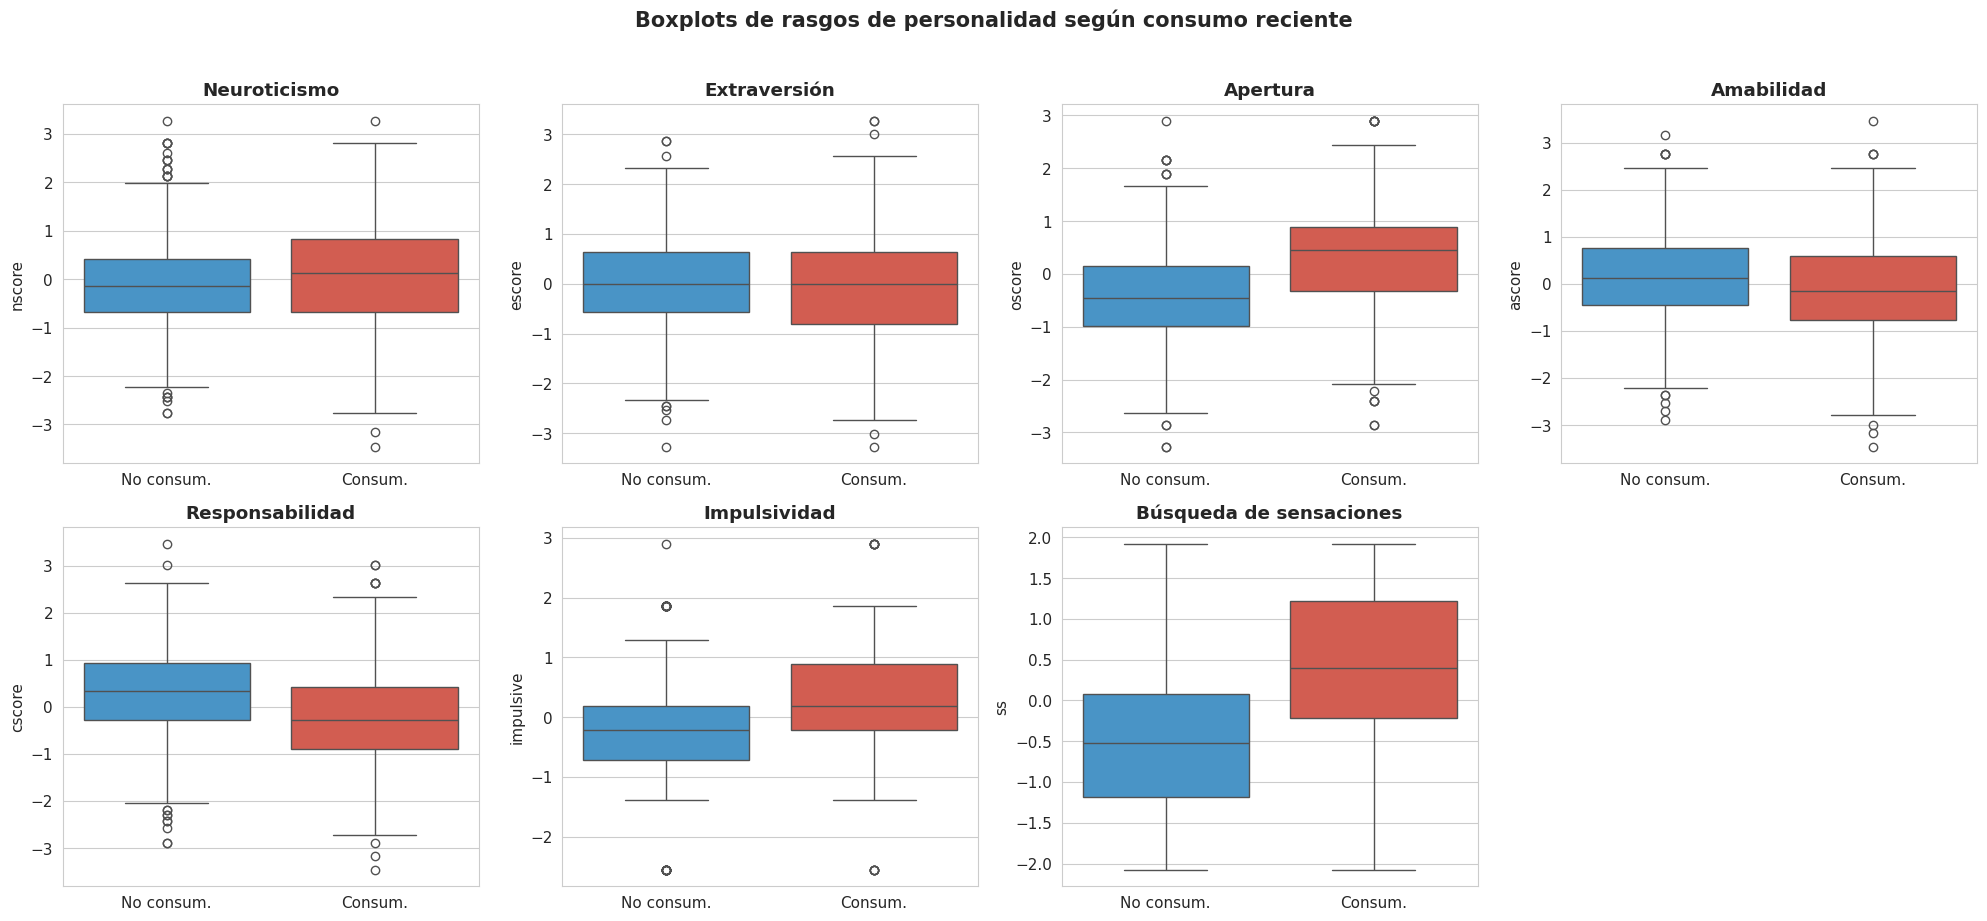

In [ ]:
# ============================================================
# B.5.3 BOXPLOTS DE PERSONALIDAD POR CLASE
# ============================================================
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, col in zip(axes.flat, PERSONALIDAD):
    sns.boxplot(data=df, x='clase', y=col, palette=paleta, ax=ax)
    ax.set_title(NOMBRES_PERS[col], fontweight='bold')
    ax.set_xlabel('')
    ax.set_xticklabels(['No consum.', 'Consum.'])
axes.flat[-1].axis('off')
plt.suptitle('Boxplots de rasgos de personalidad según consumo reciente',
             fontweight='bold', fontsize=15, y=1.02)
plt.tight_layout()
plt.show()

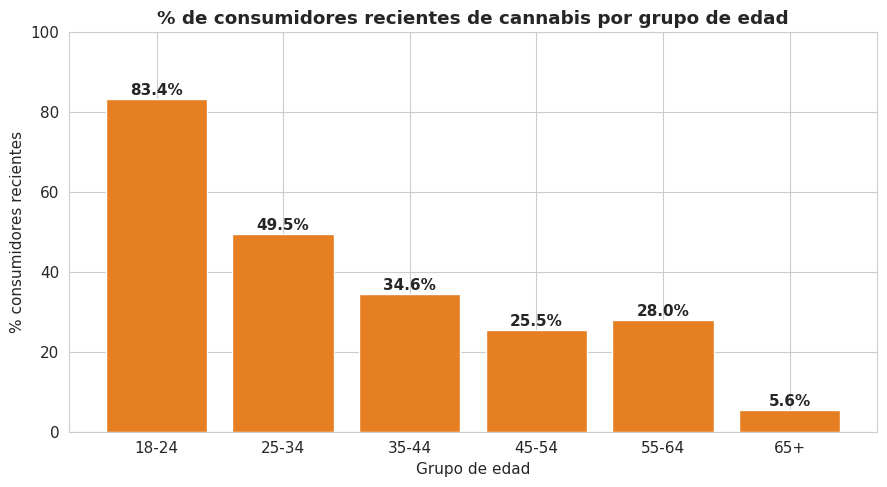

In [ ]:
# ============================================================
# B.5.4 PROPORCIÓN DE CONSUMIDORES POR GRUPO DE EDAD
# ============================================================
# La edad viene cuantificada (6 valores únicos). Según la documentación de UCI:
# 18-24, 25-34, 35-44, 45-54, 55-64, 65+ (en orden creciente del valor numérico)
etiquetas_edad = ['18-24', '25-34', '35-44', '45-54', '55-64', '65+']
valores_edad = sorted(df['age'].unique())
assert len(valores_edad) == 6, "Se esperaban 6 grupos de edad"
df['grupo_edad'] = df['age'].map(dict(zip(valores_edad, etiquetas_edad)))

prop_edad = df.groupby('grupo_edad')['objetivo'].mean().reindex(etiquetas_edad) * 100

fig, ax = plt.subplots(figsize=(9, 5))
barras = ax.bar(prop_edad.index, prop_edad.values, color='#e67e22', edgecolor='white')
for b, v in zip(barras, prop_edad.values):
    ax.text(b.get_x() + b.get_width()/2, v + 1, f'{v:.1f}%', ha='center', fontweight='bold')
ax.set_title(f'% de consumidores recientes de {DROGA} por grupo de edad', fontweight='bold')
ax.set_xlabel('Grupo de edad')
ax.set_ylabel('% consumidores recientes')
ax.set_ylim(0, 100)
plt.tight_layout()
plt.show()

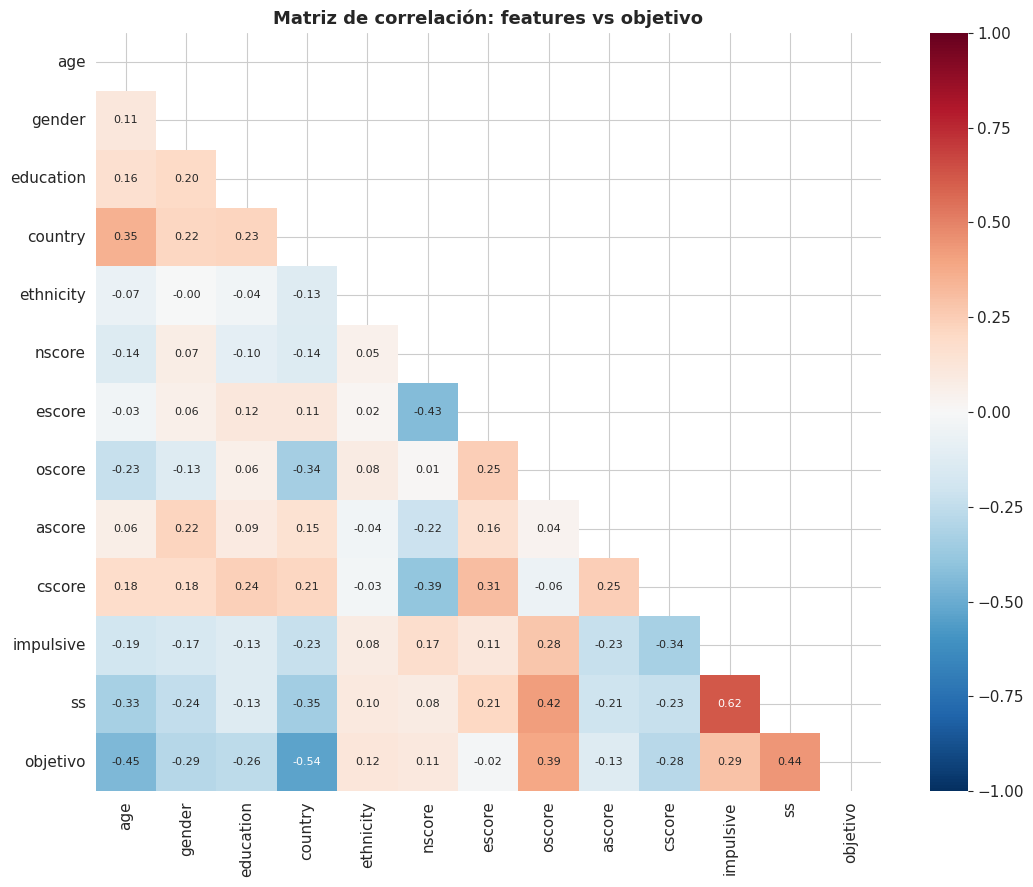

Correlación de cada feature con el objetivo (ordenadas por |r|):
  country      r = -0.535
  age          r = -0.448
  ss           r = +0.445
  oscore       r = +0.389
  impulsive    r = +0.293
  gender       r = -0.287
  cscore       r = -0.280
  education    r = -0.258
  ascore       r = -0.129
  ethnicity    r = +0.117
  nscore       r = +0.109
  escore       r = -0.022


In [ ]:
# ============================================================
# B.5.5 MAPA DE CORRELACIÓN
# ============================================================
cols_corr = list(X_raw.columns) + ['objetivo']
corr = df[cols_corr].corr()
mascara = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, mask=mascara, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, vmin=-1, vmax=1, annot_kws={'size': 8}, ax=ax)
ax.set_title('Matriz de correlación: features vs objetivo', fontweight='bold', fontsize=13)
plt.tight_layout()
plt.show()

print("Correlación de cada feature con el objetivo (ordenadas por |r|):")
corr_obj = corr['objetivo'].drop('objetivo').sort_values(key=abs, ascending=False)
for feat, r in corr_obj.items():
    print(f"  {feat:12s} r = {r:+.3f}")

### B.6 Conclusiones del EDA

El dataset tiene 1885 registros y 12 atributos, sin valores nulos ni duplicados, por lo que no requiere imputación. Todas las variables ya vienen en formato numérico porque los autores las cuantificaron, aunque `country` y `ethnicity` son en realidad variables **nominales** con valores numéricos arbitrarios, así que conviene aplicarles One-Hot Encoding para que los modelos no interpreten un orden inexistente. La variable objetivo binaria (consumo reciente de cannabis) tiene un balance razonable entre clases, por lo que accuracy es una métrica válida, aunque reportaremos F1 macro y AUC como métricas principales. Los boxplots e histogramas muestran que los consumidores recientes tienen mayor **Búsqueda de sensaciones**, **Apertura** e **Impulsividad**, y menor **Responsabilidad** y **Amabilidad**; además, el consumo es mucho más frecuente en los grupos de edad jóvenes. Las correlaciones individuales con el objetivo son moderadas, lo que anticipa que el problema no será trivial y que los modelos no lineales podrían aportar. Aunque las variables ya están aproximadamente centradas, tienen escalas distintas, así que aplicaremos `StandardScaler` (importante para SVM, KNN y Regresión Logística). Haremos el split estratificado **antes** de ajustar el escalador para evitar data leakage.

## SECCIÓN C — Preprocesamiento

Pasos: (1) tratamiento de nulos, (2) codificación de variables nominales, (3) split train/test estratificado, (4) escalado y (5) verificación de clases.

> **Nota metodológica:** hacemos el split **antes** del escalado y ajustamos el escalador **solo con train**. Si escalamos antes de dividir, la media y desviación del test contaminarían el entrenamiento (*data leakage*). Por eso el orden de C.3 y C.4 está invertido respecto a la lista de la consigna.

In [ ]:
# ============================================================
# C.1 TRATAMIENTO DE VALORES NULOS
# ============================================================
nulos_total = X_raw.isnull().sum().sum()
print(f"Valores nulos en las features: {nulos_total}")

if nulos_total == 0:
    print("✅ No hay valores nulos → no se requiere imputación ni eliminación de filas.")
else:
    # Estrategia de respaldo: mediana (robusta a outliers)
    X_raw = X_raw.fillna(X_raw.median())
    print("Se imputaron los nulos con la mediana de cada columna.")

Valores nulos en las features: 0
✅ No hay valores nulos → no se requiere imputación ni eliminación de filas.


**Justificación (C.1):** el dataset no contiene valores nulos (verificado en B.2), por lo que **no se elimina ni imputa ninguna fila**. Esto conserva los 1885 registros originales. Si hubiese nulos, imputaríamos con la mediana por ser robusta a outliers.

### C.2 Codificación de variables categóricas

Aunque todas las columnas son numéricas, **`country` y `ethnicity` son variables nominales** (categorías sin orden) cuantificadas con valores reales arbitrarios. Si las dejáramos así, modelos como la Regresión Logística, KNN o SVM interpretarían una relación de orden/distancia que no existe. Aplicamos **One-Hot Encoding** (`pd.get_dummies`).

`gender` solo tiene 2 valores (ya es binaria), y `age` y `education` son ordinales, por lo que se dejan como numéricas.

> No usamos `drop_first=True` para que la función se pueda aplicar después a datos nuevos (con pocas filas) sin perder categorías.

In [ ]:
# ============================================================
# C.2 CODIFICACIÓN DE VARIABLES NOMINALES (One-Hot)
# ============================================================
COLS_NOMINALES = ['country', 'ethnicity']
COLS_CONT = ['age', 'gender', 'education', 'nscore', 'escore', 'oscore',
             'ascore', 'cscore', 'impulsive', 'ss']

def codificar(df_features):
    """One-Hot Encoding de las variables nominales. Se reutiliza con datos nuevos."""
    d = df_features.copy()
    for c in COLS_NOMINALES:
        # Redondeamos y pasamos a texto para que los valores float se traten como categorías
        d[c] = d[c].round(5).astype(str)
    return pd.get_dummies(d, columns=COLS_NOMINALES, dtype=int)

X_enc = codificar(X_raw)
y = df['objetivo']

print(f"Shape antes de codificar:   {X_raw.shape}")
print(f"Shape después de codificar: {X_enc.shape}")
print(f"\nColumnas finales ({X_enc.shape[1]}):")
print(list(X_enc.columns))

Shape antes de codificar:   (1885, 12)
Shape después de codificar: (1885, 24)

Columnas finales (24):
['age', 'gender', 'education', 'nscore', 'escore', 'oscore', 'ascore', 'cscore', 'impulsive', 'ss', 'country_-0.09765', 'country_-0.28519', 'country_-0.46841', 'country_-0.57009', 'country_0.21128', 'country_0.24923', 'country_0.96082', 'ethnicity_-0.22166', 'ethnicity_-0.31685', 'ethnicity_-0.50212', 'ethnicity_-1.10702', 'ethnicity_0.1144', 'ethnicity_0.126', 'ethnicity_1.90725']


### C.3 Split Train/Test con estratificación

Dividimos 80% entrenamiento y 20% prueba con `test_size=0.2`, `random_state=42` y `stratify=y`. La **estratificación** asegura que la proporción de consumidores/no consumidores sea la misma en ambos conjuntos. Sin ella, por azar el test podría quedar con una proporción distinta de clases y las métricas serían poco representativas.

In [ ]:
# ============================================================
# C.3 SPLIT TRAIN / TEST ESTRATIFICADO
# ============================================================
X_train, X_test, y_train, y_test = train_test_split(
    X_enc, y,
    test_size=0.2,
    random_state=SEED,
    stratify=y
)

print(f"Train: {X_train.shape[0]} muestras | Test: {X_test.shape[0]} muestras")
print(f"Features: {X_train.shape[1]}")

Train: 1508 muestras | Test: 377 muestras
Features: 24


### C.4 Escalado de variables numéricas

Usamos **`StandardScaler`** (media 0, desviación 1) y no `MinMaxScaler` porque:
- Los atributos ya están cuantificados con distribución aproximadamente normal centrada en 0, y `StandardScaler` preserva esa forma.
- `MinMaxScaler` es muy sensible a outliers, porque un valor extremo comprime al resto.
- Modelos como **SVM (RBF)** y **KNN** dependen de distancias, y la **Regresión Logística** converge mejor con variables en la misma escala. Sin escalar, las variables de mayor rango dominarían el cálculo de distancias en SVM.

Escalamos solo las columnas continuas, **no las dummies** (0/1), y ajustamos el escalador únicamente con train.

In [ ]:
# ============================================================
# C.4 ESCALADO (fit solo en train → evita data leakage)
# ============================================================
scaler = StandardScaler()

X_train_s = X_train.copy()
X_test_s = X_test.copy()
X_train_s[COLS_CONT] = scaler.fit_transform(X_train[COLS_CONT])   # fit + transform
X_test_s[COLS_CONT] = scaler.transform(X_test[COLS_CONT])         # solo transform

print("Media de las columnas continuas en train (≈0):")
print(X_train_s[COLS_CONT].mean().round(4).to_string())
print("\nDesviación estándar en train (≈1):")
print(X_train_s[COLS_CONT].std().round(4).to_string())

Media de las columnas continuas en train (≈0):
age          0.0
gender      -0.0
education    0.0
nscore      -0.0
escore      -0.0
oscore      -0.0
ascore      -0.0
cscore       0.0
impulsive    0.0
ss           0.0

Desviación estándar en train (≈1):
age          1.0003
gender       1.0003
education    1.0003
nscore       1.0003
escore       1.0003
oscore       1.0003
ascore       1.0003
cscore       1.0003
impulsive    1.0003
ss           1.0003


### C.5 Verificación de la distribución de clases

Confirmamos que la estratificación mantuvo la proporción de clases en train y test.

Porcentaje de cada clase (%):


,Original,Train,Test
No consumidor reciente (0),47.0,47.02,46.95
Consumidor reciente (1),53.0,52.98,53.05


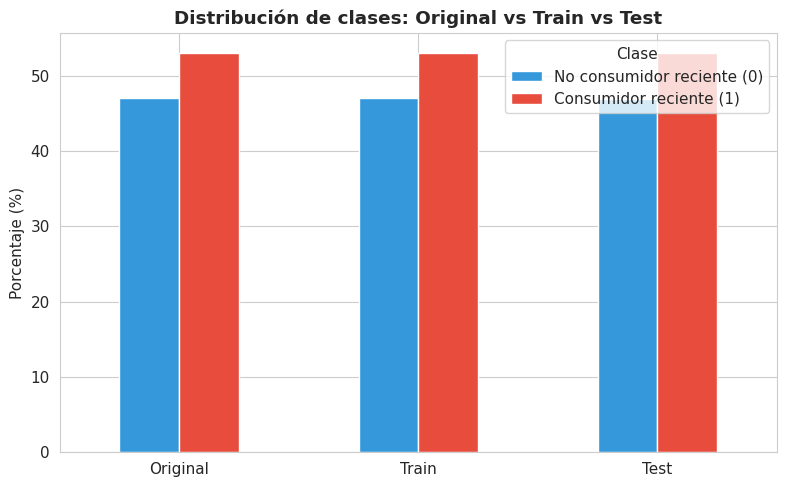

In [ ]:
# ============================================================
# C.5 VERIFICACIÓN DE DISTRIBUCIÓN DE CLASES
# ============================================================
dist = pd.DataFrame({
    'Original': y.value_counts(normalize=True).sort_index() * 100,
    'Train':    y_train.value_counts(normalize=True).sort_index() * 100,
    'Test':     y_test.value_counts(normalize=True).sort_index() * 100
}).round(2)
dist.index = ['No consumidor reciente (0)', 'Consumidor reciente (1)']
print("Porcentaje de cada clase (%):")
display(dist)

fig, ax = plt.subplots(figsize=(8, 5))
dist.T.plot(kind='bar', ax=ax, color=['#3498db', '#e74c3c'], edgecolor='white')
ax.set_title('Distribución de clases: Original vs Train vs Test', fontweight='bold')
ax.set_ylabel('Porcentaje (%)')
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
ax.legend(title='Clase')
plt.tight_layout()
plt.show()

## SECCIÓN D — Modelado (mínimo 3 modelos)

Entrenaremos **9 modelos** de familias distintas:

| Modelo | Tipo |
|---|---|
| Regresión Logística | Lineal |
| KNN | Basado en instancias |
| SVM (RBF) | Kernel |
| Árbol de Decisión | Árbol simple |
| Random Forest | Ensemble (bagging) |
| Gradient Boosting | Ensemble (boosting) |
| XGBoost | Ensemble (boosting regularizado) |
| CatBoost | Ensemble (boosting con árboles simétricos) |
| Stacking (LR + SVM + CatBoost) | Ensemble (apilamiento) |

Antes de entrenarlos, exploramos rápidamente algunos hiperparámetros clave (k de KNN y profundidad del árbol) con validación cruzada sobre **train**, sin tocar el test.

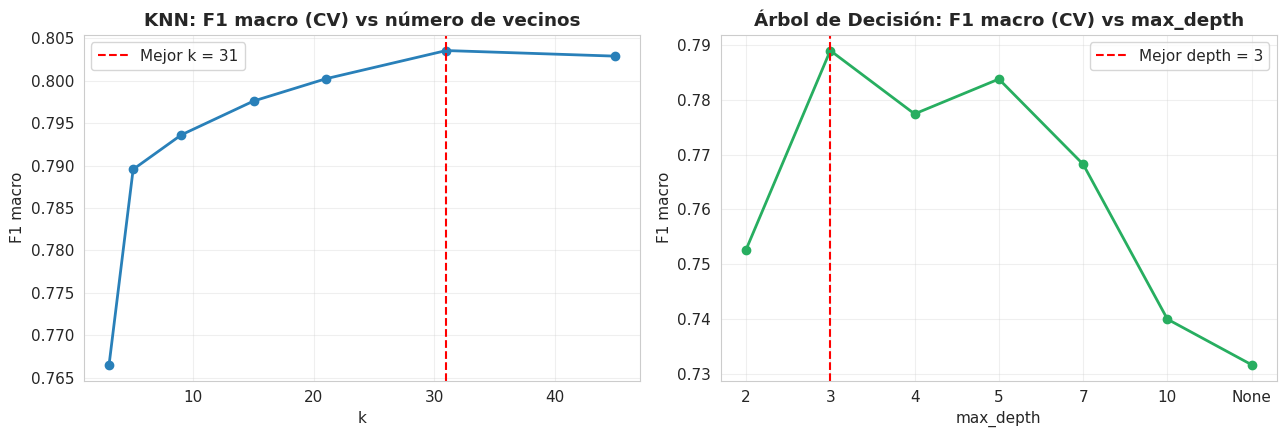

Mejor k para KNN: 31 | Mejor max_depth para el árbol: 3


In [ ]:
# ============================================================
# D.1 EXPLORACIÓN DE HIPERPARÁMETROS (validación cruzada en train)
# ============================================================
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# --- KNN: número de vecinos ---
ks = [3, 5, 9, 15, 21, 31, 45]
scores_k = [cross_val_score(KNeighborsClassifier(n_neighbors=k), X_train_s, y_train,
                            cv=cv, scoring='f1_macro').mean() for k in ks]
mejor_k = ks[int(np.argmax(scores_k))]

# --- Árbol de decisión: profundidad máxima ---
profundidades = [2, 3, 4, 5, 7, 10, None]
scores_d = [cross_val_score(DecisionTreeClassifier(max_depth=d, random_state=SEED),
                            X_train_s, y_train, cv=cv, scoring='f1_macro').mean()
            for d in profundidades]
mejor_depth = profundidades[int(np.argmax(scores_d))]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
ax1.plot(ks, scores_k, 'o-', color='#2980b9', linewidth=2)
ax1.axvline(mejor_k, color='red', linestyle='--', label=f'Mejor k = {mejor_k}')
ax1.set_title('KNN: F1 macro (CV) vs número de vecinos', fontweight='bold')
ax1.set_xlabel('k'); ax1.set_ylabel('F1 macro'); ax1.legend(); ax1.grid(True, alpha=0.3)

etiq_d = [str(d) for d in profundidades]
ax2.plot(etiq_d, scores_d, 'o-', color='#27ae60', linewidth=2)
ax2.axvline(str(mejor_depth), color='red', linestyle='--', label=f'Mejor depth = {mejor_depth}')
ax2.set_title('Árbol de Decisión: F1 macro (CV) vs max_depth', fontweight='bold')
ax2.set_xlabel('max_depth'); ax2.set_ylabel('F1 macro'); ax2.legend(); ax2.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Mejor k para KNN: {mejor_k} | Mejor max_depth para el árbol: {mejor_depth}")

MODELO: Regresión Logística
               precision    recall  f1-score   support

No consumidor     0.8229    0.8136    0.8182       177
   Consumidor     0.8366    0.8450    0.8408       200

     accuracy                         0.8302       377
    macro avg     0.8297    0.8293    0.8295       377
 weighted avg     0.8302    0.8302    0.8302       377



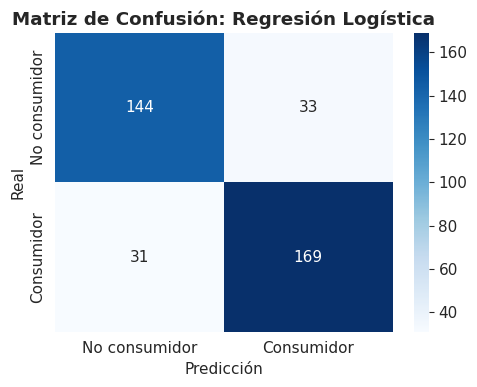

MODELO: KNN
               precision    recall  f1-score   support

No consumidor     0.7566    0.8079    0.7814       177
   Consumidor     0.8191    0.7700    0.7938       200

     accuracy                         0.7878       377
    macro avg     0.7879    0.7890    0.7876       377
 weighted avg     0.7898    0.7878    0.7880       377



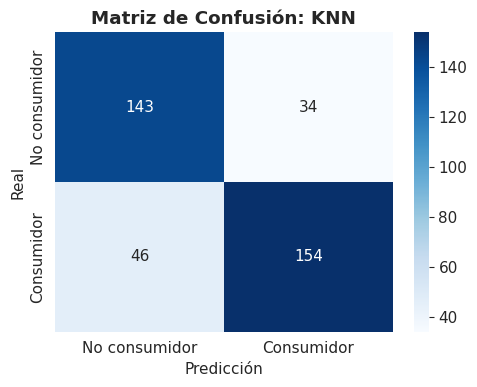

MODELO: SVM (RBF)
               precision    recall  f1-score   support

No consumidor     0.7874    0.7740    0.7806       177
   Consumidor     0.8030    0.8150    0.8089       200

     accuracy                         0.7958       377
    macro avg     0.7952    0.7945    0.7948       377
 weighted avg     0.7956    0.7958    0.7956       377



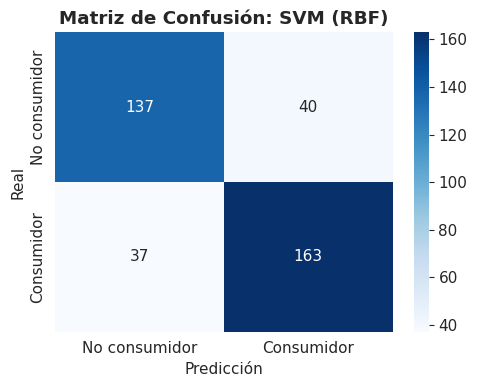

MODELO: Árbol de Decisión
               precision    recall  f1-score   support

No consumidor     0.7895    0.8475    0.8174       177
   Consumidor     0.8556    0.8000    0.8269       200

     accuracy                         0.8223       377
    macro avg     0.8225    0.8237    0.8222       377
 weighted avg     0.8246    0.8223    0.8224       377



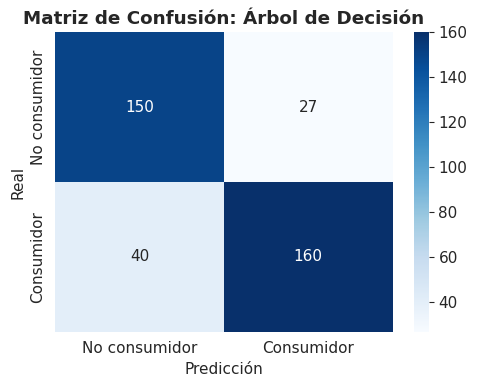

MODELO: Random Forest
               precision    recall  f1-score   support

No consumidor     0.8144    0.7684    0.7907       177
   Consumidor     0.8048    0.8450    0.8244       200

     accuracy                         0.8090       377
    macro avg     0.8096    0.8067    0.8075       377
 weighted avg     0.8093    0.8090    0.8086       377



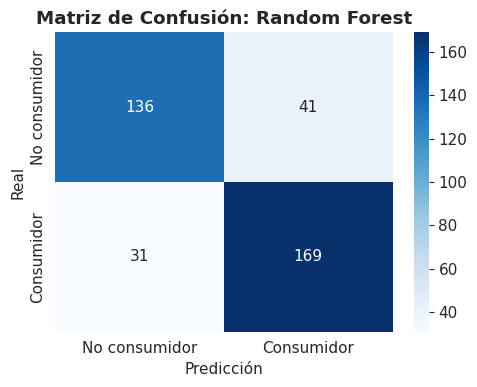

MODELO: Gradient Boosting
               precision    recall  f1-score   support

No consumidor     0.8246    0.7966    0.8103       177
   Consumidor     0.8252    0.8500    0.8374       200

     accuracy                         0.8249       377
    macro avg     0.8249    0.8233    0.8239       377
 weighted avg     0.8249    0.8249    0.8247       377



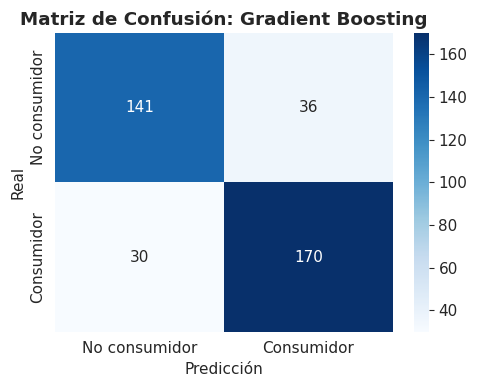

MODELO: XGBoost
               precision    recall  f1-score   support

No consumidor     0.8218    0.8079    0.8148       177
   Consumidor     0.8325    0.8450    0.8387       200

     accuracy                         0.8276       377
    macro avg     0.8272    0.8265    0.8268       377
 weighted avg     0.8275    0.8276    0.8275       377



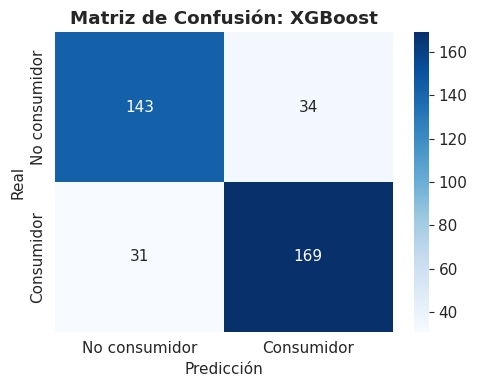

MODELO: CatBoost
               precision    recall  f1-score   support

No consumidor     0.8092    0.7910    0.8000       177
   Consumidor     0.8186    0.8350    0.8267       200

     accuracy                         0.8143       377
    macro avg     0.8139    0.8130    0.8134       377
 weighted avg     0.8142    0.8143    0.8142       377



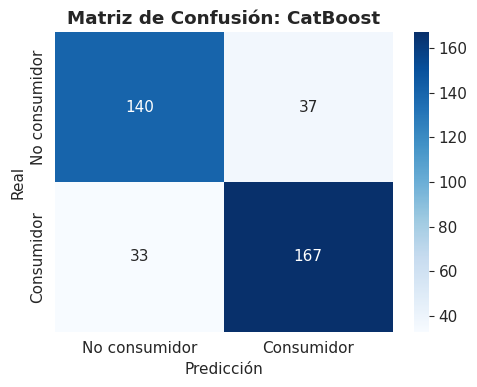

MODELO: Stacking (LR+SVM+CatBoost)
               precision    recall  f1-score   support

No consumidor     0.8274    0.7853    0.8058       177
   Consumidor     0.8182    0.8550    0.8362       200

     accuracy                         0.8223       377
    macro avg     0.8228    0.8202    0.8210       377
 weighted avg     0.8225    0.8223    0.8219       377



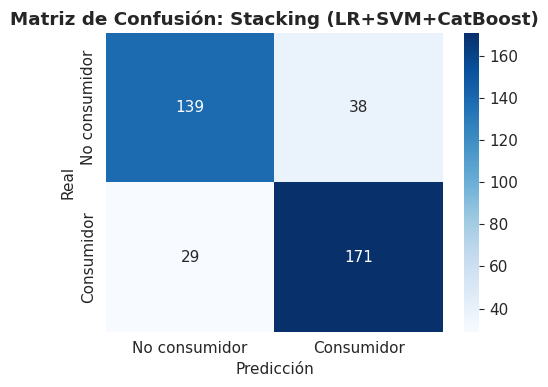


✅ Los 9 modelos fueron entrenados y evaluados.


In [ ]:
# ============================================================
# D.2 DEFINICIÓN, ENTRENAMIENTO Y EVALUACIÓN DE LOS 9 MODELOS
# ============================================================
modelos = {
    'Regresión Logística': LogisticRegression(max_iter=1000, random_state=SEED),
    'KNN':                 KNeighborsClassifier(n_neighbors=mejor_k),
    'SVM (RBF)':           SVC(kernel='rbf', probability=True, random_state=SEED),
    'Árbol de Decisión':   DecisionTreeClassifier(max_depth=mejor_depth, random_state=SEED),
    'Random Forest':       RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1),
    'Gradient Boosting':   GradientBoostingClassifier(random_state=SEED),

    # --- XGBoost: boosting con regularización L1/L2 y submuestreo ---
    # Árboles poco profundos + learning rate bajo + muchas iteraciones:
    # con solo ~1500 filas, esto reduce el sobreajuste frente al GB por defecto.
    'XGBoost': XGBClassifier(
        n_estimators=400, learning_rate=0.03, max_depth=3,
        subsample=0.8, colsample_bytree=0.8, min_child_weight=3,
        reg_lambda=1.0, eval_metric='logloss',
        random_state=SEED, n_jobs=-1),

    # --- CatBoost: árboles simétricos (oblivious), muy robusto en datasets pequeños ---
    'CatBoost': CatBoostClassifier(
        iterations=600, learning_rate=0.03, depth=4, l2_leaf_reg=5,
        random_seed=SEED, verbose=0),

    # --- Stacking: combina un modelo lineal, uno de kernel y uno de boosting ---
    # Un meta-modelo (Regresión Logística) aprende a ponderar sus probabilidades.
    # Aprovecha que la relación es casi lineal (LR) pero añade las interacciones
    # no lineales que capturan SVM y CatBoost.
    'Stacking (LR+SVM+CatBoost)': StackingClassifier(
        estimators=[
            ('lr',  LogisticRegression(max_iter=1000, random_state=SEED)),
            ('svm', SVC(kernel='rbf', probability=True, random_state=SEED)),
            ('cat', CatBoostClassifier(iterations=600, learning_rate=0.03, depth=4,
                                       l2_leaf_reg=5, random_seed=SEED, verbose=0)),
        ],
        final_estimator=LogisticRegression(max_iter=1000, random_state=SEED),
        stack_method='predict_proba',
        cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED),
        n_jobs=-1),
}

NOMBRES_CLASES = ['No consumidor', 'Consumidor']
resultados = []       # métricas de cada modelo
probas_test = {}      # probabilidades (para curvas ROC)
preds_test = {}

def evaluar_modelo(nombre, modelo):
    """Entrena con train, predice en test y muestra reporte + heatmap de confusión."""
    modelo.fit(X_train_s, y_train)
    y_pred = modelo.predict(X_test_s)
    y_proba = modelo.predict_proba(X_test_s)[:, 1]

    print("=" * 60)
    print(f"MODELO: {nombre}")
    print("=" * 60)
    print(classification_report(y_test, y_pred, target_names=NOMBRES_CLASES, digits=4))

    # Matriz de confusión (heatmap)
    cm = confusion_matrix(y_test, y_pred)
    fig, ax = plt.subplots(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=NOMBRES_CLASES, yticklabels=NOMBRES_CLASES, ax=ax)
    ax.set_xlabel('Predicción'); ax.set_ylabel('Real')
    ax.set_title(f'Matriz de Confusión: {nombre}', fontweight='bold')
    plt.tight_layout()
    plt.show()

    resultados.append({
        'Modelo': nombre,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision macro': precision_score(y_test, y_pred, average='macro'),
        'Recall macro': recall_score(y_test, y_pred, average='macro'),
        'F1 macro': f1_score(y_test, y_pred, average='macro'),
        'AUC': roc_auc_score(y_test, y_proba),
    })
    probas_test[nombre] = y_proba
    preds_test[nombre] = y_pred

for nombre, modelo in modelos.items():
    evaluar_modelo(nombre, modelo)

print(f"\n✅ Los {len(modelos)} modelos fueron entrenados y evaluados.")

## SECCIÓN E — Evaluación Comparativa

Comparamos los 9 modelos con una tabla resumen, un gráfico de barras y curvas ROC superpuestas, y cerramos con un análisis escrito.

**Criterio de selección: AUC.** Usamos el AUC como métrica principal para elegir el modelo porque **no depende del umbral de decisión**: mide qué tan bien el modelo ordena a las personas según su probabilidad de consumo. El F1 macro sí depende del umbral (0.5 por defecto), y ese umbral se puede ajustar después (sección F), por lo que conviene elegir primero el modelo que mejor separa las clases y luego calibrar el umbral.

TABLA RESUMEN (ordenada por AUC, métrica de selección):


,Accuracy,Precision macro,Recall macro,F1 macro,AUC
Modelo,,,,,
Stacking (LR+SVM+CatBoost),0.8223,0.8228,0.8202,0.8210,0.9021
Regresión Logística,0.8302,0.8297,0.8293,0.8295,0.8987
XGBoost,0.8276,0.8272,0.8265,0.8268,0.8975
CatBoost,0.8143,0.8139,0.8130,0.8134,0.8969
Random Forest,0.8090,0.8096,0.8067,0.8075,0.8957
SVM (RBF),0.7958,0.7952,0.7945,0.7948,0.8956
Gradient Boosting,0.8249,0.8249,0.8233,0.8239,0.8952
KNN,0.7878,0.7879,0.7890,0.7876,0.8798
Árbol de Decisión,0.8223,0.8225,0.8237,0.8222,0.8629


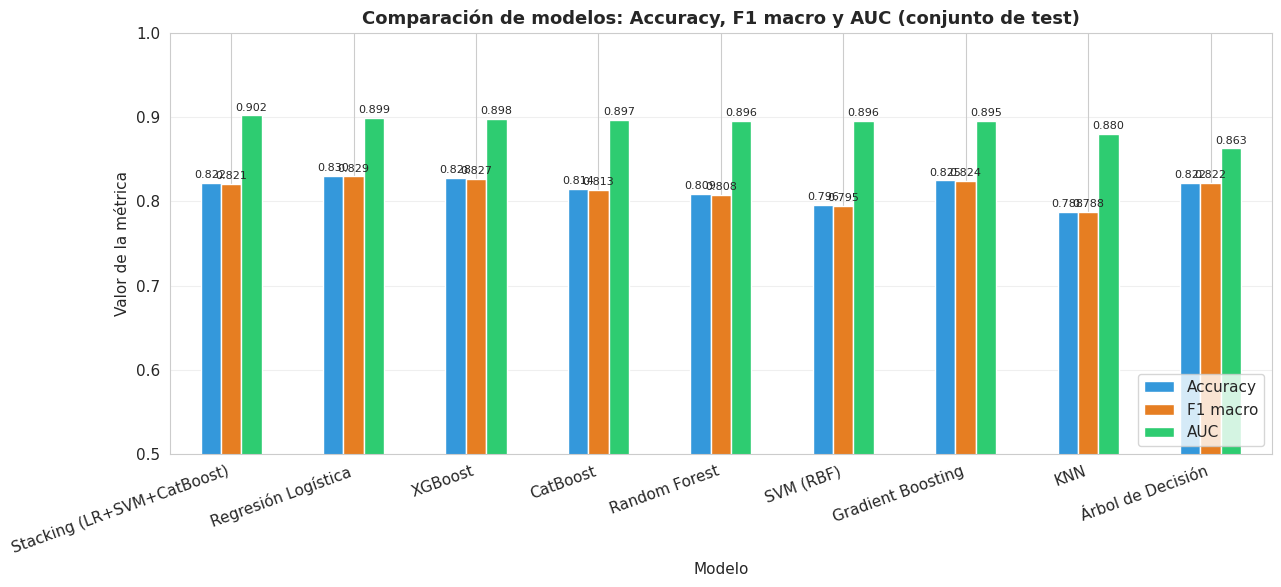

In [ ]:
# ============================================================
# E.1 TABLA RESUMEN  |  E.2 GRÁFICO DE BARRAS
# ============================================================
df_res = pd.DataFrame(resultados).set_index('Modelo').sort_values('AUC', ascending=False)
print("TABLA RESUMEN (ordenada por AUC, métrica de selección):")
display(df_res.round(4))

# Gráfico de barras agrupadas
metricas_graf = ['Accuracy', 'F1 macro', 'AUC']
ax = df_res[metricas_graf].plot(kind='bar', figsize=(13, 6),
                                color=['#3498db', '#e67e22', '#2ecc71'], edgecolor='white')
ax.set_title('Comparación de modelos: Accuracy, F1 macro y AUC (conjunto de test)',
             fontweight='bold', fontsize=13)
ax.set_ylabel('Valor de la métrica')
ax.set_ylim(0.5, 1.0)
ax.set_xticklabels(ax.get_xticklabels(), rotation=20, ha='right')
ax.legend(loc='lower right')
ax.grid(True, alpha=0.3, axis='y')
for cont in ax.containers:
    ax.bar_label(cont, fmt='%.3f', fontsize=8, padding=2)
plt.tight_layout()
plt.show()

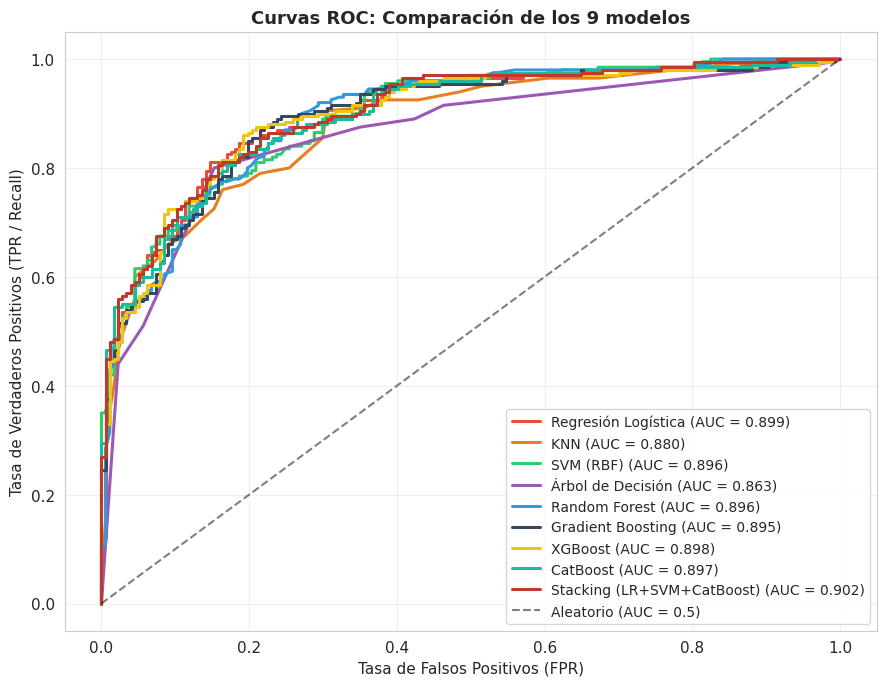

In [ ]:
# ============================================================
# E.3 CURVAS ROC SUPERPUESTAS (todos los modelos)
# ============================================================
fig, ax = plt.subplots(figsize=(9, 7))
colores_roc = ['#e74c3c', '#e67e22', '#2ecc71', '#9b59b6', '#3498db', '#34495e',
               '#f1c40f', '#1abc9c', '#c0392b']

for (nombre, proba), color in zip(probas_test.items(), colores_roc):
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc_val = roc_auc_score(y_test, proba)
    ax.plot(fpr, tpr, linewidth=2.2, color=color, label=f'{nombre} (AUC = {auc_val:.3f})')

ax.plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Aleatorio (AUC = 0.5)')
ax.set_xlabel('Tasa de Falsos Positivos (FPR)')
ax.set_ylabel('Tasa de Verdaderos Positivos (TPR / Recall)')
ax.set_title(f'Curvas ROC: Comparación de los {len(probas_test)} modelos', fontweight='bold', fontsize=13)
ax.legend(loc='lower right', fontsize=10)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# E.4 SELECCIÓN DEL MEJOR MODELO + RESUMEN PARA EL ANÁLISIS
# ============================================================
# Criterio: mayor AUC en test (no depende del umbral de decisión)
mejor_modelo = df_res['AUC'].idxmax()
peor_modelo = df_res['AUC'].idxmin()

print(f"🏆 MEJOR MODELO (mayor AUC): {mejor_modelo}")
print(df_res.loc[mejor_modelo].round(4).to_string())

print(f"\n📉 Peor modelo por AUC: {peor_modelo} (AUC = {df_res.loc[peor_modelo, 'AUC']:.4f})")
print(f"   Peor modelo por F1 macro: {df_res['F1 macro'].idxmin()} "
      f"(F1 macro = {df_res['F1 macro'].min():.4f})")
print(f"\nDiferencia de AUC entre el mejor y el peor: {df_res['AUC'].max() - df_res['AUC'].min():.4f}")
print(f"Diferencia de F1 macro entre el mejor y el peor: {df_res['F1 macro'].max() - df_res['F1 macro'].min():.4f}")

# Ventaja del modelo elegido frente a la Regresión Logística (modelo base)
if mejor_modelo != 'Regresión Logística':
    d_auc = df_res.loc[mejor_modelo, 'AUC'] - df_res.loc['Regresión Logística', 'AUC']
    print(f"\nMejora de AUC de {mejor_modelo} frente a la Regresión Logística: {d_auc:+.4f}")

🏆 MEJOR MODELO (mayor AUC): Stacking (LR+SVM+CatBoost)
Accuracy           0.8223
Precision macro    0.8228
Recall macro       0.8202
F1 macro           0.8210
AUC                0.9021

📉 Peor modelo por AUC: Árbol de Decisión (AUC = 0.8629)
   Peor modelo por F1 macro: KNN (F1 macro = 0.7876)

Diferencia de AUC entre el mejor y el peor: 0.0392
Diferencia de F1 macro entre el mejor y el peor: 0.0419

Mejora de AUC de Stacking (LR+SVM+CatBoost) frente a la Regresión Logística: +0.0034


### E.4 Análisis comparativo

Al comparar los nueve modelos sobre el conjunto de test, el mejor fue el Stacking (LR + SVM + CatBoost). Obtuvo el AUC más alto de todos (0.9021), con un F1 macro de 0.8210 y un accuracy de 0.8223. El Stacking combina tres modelos de familias distintas:

una Regresión Logística, que captura la parte aproximadamente lineal de la relación entre personalidad y consumo;
un SVM con kernel RBF;
CatBoost, que captura interacciones no lineales entre variables.

Un meta-modelo (otra Regresión Logística) aprende cuánto confiar en cada uno. Por eso el conjunto ordena mejor a las personas que cualquiera de sus componentes por separado: Regresión Logística 0.8987, CatBoost 0.8969 y SVM 0.8956 de AUC.

Por AUC, el peor modelo fue el Árbol de Decisión (0.8629), limitado por su baja profundidad (max_depth = 3). Por F1 macro, el peor fue KNN (0.7876), un modelo sensible a la elección de k y a la escala de las variables. Las diferencias entre modelos son pequeñas: 0.0392 en AUC y 0.0419 en F1 macro entre el mejor y el peor. Esto indica que buena parte de la información predictiva se captura con relaciones simples. De hecho, la Regresión Logística quedó segunda en AUC (0.8987), solo 0.0034 por debajo del Stacking, y obtuvo el mejor F1 macro (0.8295) y el mejor accuracy (0.8303) con el umbral de 0.5. La validación cruzada repetida (E.5) confirma el mismo orden en AUC: Stacking 0.8958 ± 0.0111 frente a la Regresión Logística 0.8935 ± 0.0124. Sin embargo, la diferencia es menor que la desviación estándar, así que no es concluyente.

En cuanto a trade-offs, el Stacking es más costoso de entrenar y menos interpretable que un modelo lineal, pero ese costo es aceptable para un dataset de este tamaño. Elegimos el Stacking (LR + SVM + CatBoost) para optimizarlo en la siguiente sección.

### E.5 Verificación de estabilidad con validación cruzada repetida

Como el test es pequeño (377 muestras), verificamos también el desempeño de los modelos con **validación cruzada repetida** (5 folds × 3 repeticiones) sobre train, reportando **AUC** y **F1 macro** con su desviación estándar. Esta tabla es una comprobación complementaria: el modelo ya fue elegido en E.4 por AUC. Si dos modelos difieren menos que su desviación estándar, la diferencia no es concluyente.

Validación cruzada repetida 5x3 sobre train (ordenada por AUC):


,AUC CV,AUC desv.,F1 macro CV,F1 desv.
Modelo,,,,
Stacking (LR+SVM+CatBoost),0.8958,0.0111,0.8170,0.0199
Regresión Logística,0.8935,0.0124,0.8112,0.0241
XGBoost,0.8899,0.0126,0.8152,0.0175
SVM (RBF),0.8899,0.0101,0.8150,0.0165
Random Forest,0.8898,0.0106,0.8198,0.0183
CatBoost,0.8893,0.0122,0.8150,0.0225
Gradient Boosting,0.8858,0.0141,0.8122,0.0207
KNN,0.8826,0.0126,0.8012,0.0138
Árbol de Decisión,0.8506,0.0146,0.7849,0.0154


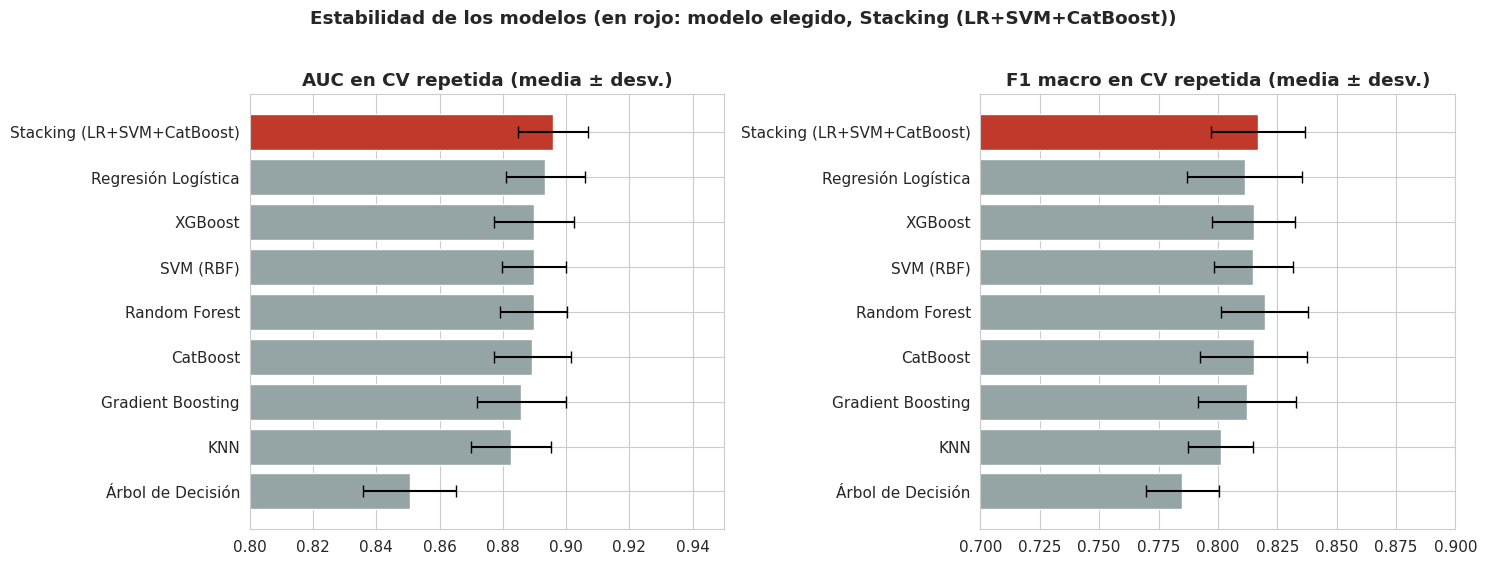


Modelo elegido: Stacking (LR+SVM+CatBoost)
   AUC CV:      0.8958 ± 0.0111
   F1 macro CV: 0.8170 ± 0.0199


In [ ]:
# ============================================================
# E.5 VERIFICACIÓN CON VALIDACIÓN CRUZADA REPETIDA (train)
# ============================================================
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate

cv_rep = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)

filas_cv = []
for nombre in modelos:
    r = cross_validate(clone(modelos[nombre]), X_train_s, y_train, cv=cv_rep,
                       scoring={'auc': 'roc_auc', 'f1': 'f1_macro'}, n_jobs=-1)
    filas_cv.append({'Modelo': nombre,
                     'AUC CV': r['test_auc'].mean(), 'AUC desv.': r['test_auc'].std(),
                     'F1 macro CV': r['test_f1'].mean(), 'F1 desv.': r['test_f1'].std()})

df_cv = pd.DataFrame(filas_cv).set_index('Modelo').sort_values('AUC CV', ascending=False)
print("Validación cruzada repetida 5x3 sobre train (ordenada por AUC):")
display(df_cv.round(4))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5))
colores_cv = ['#c0392b' if m == mejor_modelo else '#95a5a6' for m in df_cv.index]
ax1.barh(df_cv.index, df_cv['AUC CV'], xerr=df_cv['AUC desv.'], color=colores_cv, capsize=4)
ax1.set_xlim(0.8, 0.95); ax1.invert_yaxis()
ax1.set_title('AUC en CV repetida (media ± desv.)', fontweight='bold')
ax2.barh(df_cv.index, df_cv['F1 macro CV'], xerr=df_cv['F1 desv.'], color=colores_cv, capsize=4)
ax2.set_xlim(0.7, 0.9); ax2.invert_yaxis()
ax2.set_title('F1 macro en CV repetida (media ± desv.)', fontweight='bold')
plt.suptitle(f'Estabilidad de los modelos (en rojo: modelo elegido, {mejor_modelo})',
             fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print(f"\nModelo elegido: {mejor_modelo}")
print(f"   AUC CV:      {df_cv.loc[mejor_modelo, 'AUC CV']:.4f} ± {df_cv.loc[mejor_modelo, 'AUC desv.']:.4f}")
print(f"   F1 macro CV: {df_cv.loc[mejor_modelo, 'F1 macro CV']:.4f} ± {df_cv.loc[mejor_modelo, 'F1 desv.']:.4f}")

## SECCIÓN F — Modelo Final y Serialización

Tomamos el mejor modelo de la sección E, el **Stacking (LR + SVM + CatBoost)**, y lo mejoramos en dos pasos:

1. **GridSearchCV** (validación cruzada estratificada de 5 folds sobre train) sobre **3 hiperparámetros**: la regularización del meta-modelo (`final_estimator__C`), si el meta-modelo recibe también las variables originales además de las probabilidades (`passthrough`), y la profundidad de los árboles de CatBoost (`cat__depth`). Se evalúan AUC y F1 macro, y se elige la combinación con mayor AUC.
2. **Ajuste del umbral de decisión**: en lugar de clasificar como consumidor a quien tenga probabilidad ≥ 0.5, buscamos el umbral que maximiza el F1 macro usando predicciones *out-of-fold* sobre train (sin tocar el test).

Después evaluamos en test, serializamos con `joblib` (incluyendo el umbral) y demostramos la carga y predicción sobre datos nuevos.

In [ ]:
# ============================================================
# F.1 GRIDSEARCHCV SOBRE EL MEJOR MODELO
# ============================================================
# Rejillas de hiperparámetros por modelo (todas con ≥2 hiperparámetros)
param_grids = {
    'Regresión Logística': {'C': [0.01, 0.1, 1, 10, 100],
                            'class_weight': [None, 'balanced']},
    'KNN':                 {'n_neighbors': [5, 11, 15, 21, 31, 45],
                            'weights': ['uniform', 'distance'],
                            'p': [1, 2]},
    'SVM (RBF)':           {'C': [0.1, 1, 10],
                            'gamma': ['scale', 0.01, 0.1],
                            'kernel': ['rbf', 'linear']},
    'Árbol de Decisión':   {'max_depth': [3, 5, 7, 10],
                            'min_samples_leaf': [1, 5, 10, 20],
                            'criterion': ['gini', 'entropy']},
    'Random Forest':       {'n_estimators': [200, 400],
                            'max_depth': [None, 5, 10],
                            'min_samples_leaf': [1, 3, 5]},
    'Gradient Boosting':   {'n_estimators': [100, 200],
                            'learning_rate': [0.03, 0.1],
                            'max_depth': [2, 3]},
    'XGBoost':             {'n_estimators': [300, 600],
                            'learning_rate': [0.01, 0.03, 0.05],
                            'max_depth': [2, 3, 4]},
    'CatBoost':            {'iterations': [400, 800],
                            'learning_rate': [0.02, 0.05],
                            'depth': [3, 4, 6]},
    'Stacking (LR+SVM+CatBoost)': {'final_estimator__C': [0.1, 1, 10],
                            'passthrough': [False, True],
                            'cat__depth': [3, 4]},
}

print(f"🏆 Modelo seleccionado para optimizar: {mejor_modelo}")
print(f"Hiperparámetros a explorar: {param_grids[mejor_modelo]}\n")

grid = GridSearchCV(
    estimator=clone(modelos[mejor_modelo]),   # copia sin entrenar del mejor modelo
    param_grid=param_grids[mejor_modelo],
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED),
    scoring={'auc': 'roc_auc', 'f1': 'f1_macro'},
    refit='auc',            # nos quedamos con la combinación de mayor AUC
    n_jobs=-1,
    verbose=1
)
grid.fit(X_train_s, y_train)

i_best = grid.best_index_
print(f"\n✅ Mejores hiperparámetros: {grid.best_params_}")
print(f"   AUC en CV (train):      {grid.cv_results_['mean_test_auc'][i_best]:.4f}")
print(f"   F1 macro en CV (train): {grid.cv_results_['mean_test_f1'][i_best]:.4f}")

modelo_final = grid.best_estimator_

🏆 Modelo seleccionado para optimizar: Stacking (LR+SVM+CatBoost)
Hiperparámetros a explorar: {'final_estimator__C': [0.1, 1, 10], 'passthrough': [False, True], 'cat__depth': [3, 4]}

Fitting 5 folds for each of 12 candidates, totalling 60 fits

✅ Mejores hiperparámetros: {'cat__depth': 4, 'final_estimator__C': 1, 'passthrough': False}
   AUC en CV (train):      0.8958
   F1 macro en CV (train): 0.8157


Stacking (LR+SVM+CatBoost) — validación cruzada 5 folds (train)
  Por defecto:  AUC = 0.8958 | F1 macro = 0.8157
  Optimizado:   AUC = 0.8958 | F1 macro = 0.8157

🎯 Umbral óptimo (máx. F1 macro out-of-fold): 0.57
   F1 macro OOF con umbral 0.50:     0.8158
   F1 macro OOF con umbral 0.57:     0.8182


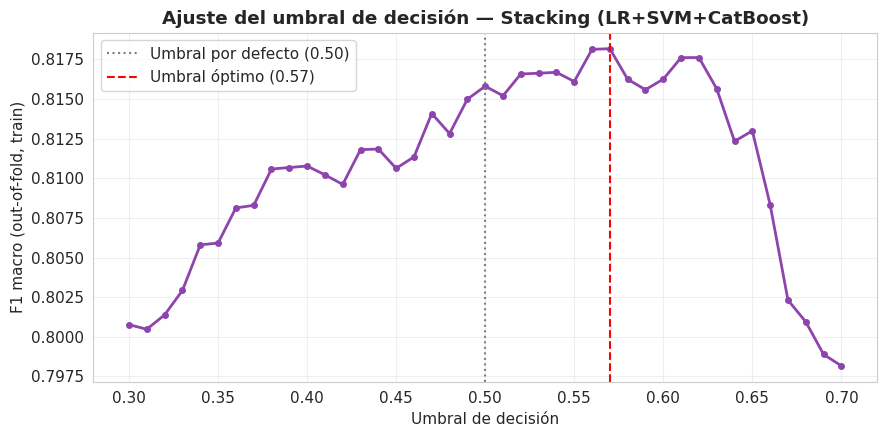

In [ ]:
# ============================================================
# F.1b COMPARACIÓN EN CV (por defecto vs optimizado) Y AJUSTE DEL UMBRAL
# ============================================================
from sklearn.model_selection import cross_validate, cross_val_predict

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)   # mismos folds que el GridSearch
base = cross_validate(clone(modelos[mejor_modelo]), X_train_s, y_train, cv=cv,
                      scoring={'auc': 'roc_auc', 'f1': 'f1_macro'}, n_jobs=-1)
print(f"{mejor_modelo} — validación cruzada 5 folds (train)")
print(f"  Por defecto:  AUC = {base['test_auc'].mean():.4f} | F1 macro = {base['test_f1'].mean():.4f}")
print(f"  Optimizado:   AUC = {grid.cv_results_['mean_test_auc'][i_best]:.4f} | "
      f"F1 macro = {grid.cv_results_['mean_test_f1'][i_best]:.4f}")

# --- Ajuste del umbral de decisión con probabilidades out-of-fold (solo train) ---
proba_oof = cross_val_predict(clone(modelo_final), X_train_s, y_train, cv=cv,
                              method='predict_proba', n_jobs=-1)[:, 1]
umbrales = np.round(np.arange(0.30, 0.71, 0.01), 2)
f1_umbral = [f1_score(y_train, (proba_oof >= u).astype(int), average='macro') for u in umbrales]
UMBRAL = float(umbrales[int(np.argmax(f1_umbral))])

print(f"\n🎯 Umbral óptimo (máx. F1 macro out-of-fold): {UMBRAL:.2f}")
print(f"   F1 macro OOF con umbral 0.50:     {f1_score(y_train, (proba_oof >= 0.5).astype(int), average='macro'):.4f}")
print(f"   F1 macro OOF con umbral {UMBRAL:.2f}:     {max(f1_umbral):.4f}")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(umbrales, f1_umbral, 'o-', color='#8e44ad', linewidth=2, markersize=4)
ax.axvline(0.5, color='gray', linestyle=':', label='Umbral por defecto (0.50)')
ax.axvline(UMBRAL, color='red', linestyle='--', label=f'Umbral óptimo ({UMBRAL:.2f})')
ax.set_xlabel('Umbral de decisión'); ax.set_ylabel('F1 macro (out-of-fold, train)')
ax.set_title(f'Ajuste del umbral de decisión — {mejor_modelo}', fontweight='bold')
ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

EVALUACIÓN EN TEST: Stacking (LR+SVM+CatBoost) OPTIMIZADO (umbral = 0.57)
               precision    recall  f1-score   support

No consumidor     0.8000    0.8136    0.8067       177
   Consumidor     0.8325    0.8200    0.8262       200

     accuracy                         0.8170       377
    macro avg     0.8162    0.8168    0.8165       377
 weighted avg     0.8172    0.8170    0.8171       377



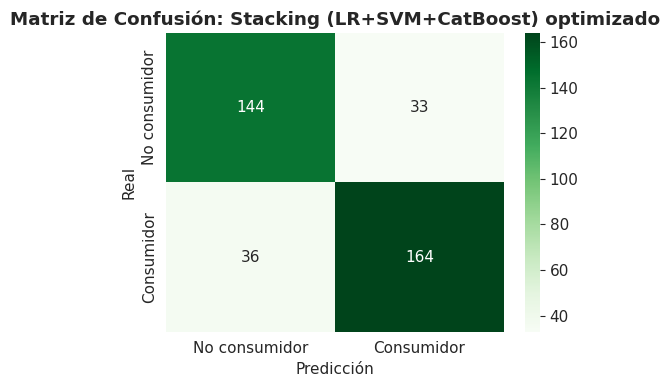


Comparación en test: modelo base vs Stacking antes y después de optimizar:


,Regresión Logística (base),Stacking por defecto,Stacking optimizado
Accuracy,0.8302,0.8223,0.8170
F1 macro,0.8295,0.8210,0.8165
AUC,0.8987,0.9021,0.9021


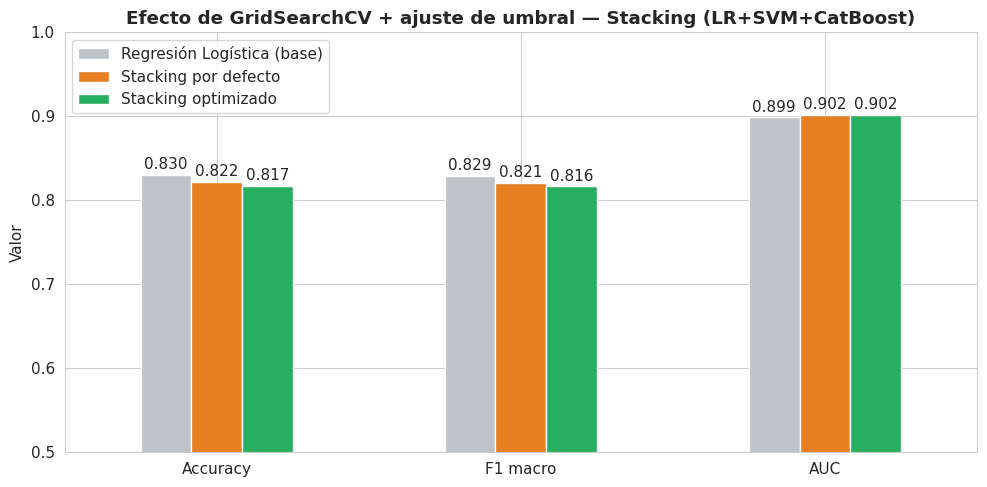

In [ ]:
# ============================================================
# F.2 EVALUACIÓN DEL MODELO OPTIMIZADO EN TEST
# ============================================================
y_proba_f = modelo_final.predict_proba(X_test_s)[:, 1]
y_pred_f = (y_proba_f >= UMBRAL).astype(int)          # aplicamos el umbral ajustado

print("=" * 60)
print(f"EVALUACIÓN EN TEST: {mejor_modelo} OPTIMIZADO (umbral = {UMBRAL:.2f})")
print("=" * 60)
print(classification_report(y_test, y_pred_f, target_names=NOMBRES_CLASES, digits=4))

cm = confusion_matrix(y_test, y_pred_f)
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=NOMBRES_CLASES, yticklabels=NOMBRES_CLASES, ax=ax)
ax.set_xlabel('Predicción'); ax.set_ylabel('Real')
ax.set_title(f'Matriz de Confusión: {mejor_modelo} optimizado', fontweight='bold')
plt.tight_layout()
plt.show()

# --- Comparación antes vs después de la optimización ---
comp = pd.DataFrame({
    'Regresión Logística (base)': df_res.loc['Regresión Logística', ['Accuracy', 'F1 macro', 'AUC']].values,
    'Stacking por defecto': df_res.loc[mejor_modelo, ['Accuracy', 'F1 macro', 'AUC']].values,
    'Stacking optimizado': [accuracy_score(y_test, y_pred_f),
                            f1_score(y_test, y_pred_f, average='macro'),
                            roc_auc_score(y_test, y_proba_f)]
}, index=['Accuracy', 'F1 macro', 'AUC'])
print("\nComparación en test: modelo base vs Stacking antes y después de optimizar:")
display(comp.round(4))

ax = comp.plot(kind='bar', figsize=(10, 5), color=['#bdc3c7', '#e67e22', '#27ae60'], edgecolor='white')
ax.set_title(f'Efecto de GridSearchCV + ajuste de umbral — {mejor_modelo}', fontweight='bold')
ax.set_ylim(0.5, 1.0); ax.set_ylabel('Valor')
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
for cont in ax.containers:
    ax.bar_label(cont, fmt='%.3f', padding=2)
plt.tight_layout()
plt.show()

### F.3 Serialización del modelo final con `joblib.dump()`

Guardamos en un único archivo **todo lo necesario para predecir**: el modelo entrenado, el `StandardScaler` ajustado, el orden exacto de las columnas, la lista de columnas a escalar y el **umbral de decisión** ajustado. Si guardáramos solo el modelo, al usarlo después no podríamos reproducir el preprocesamiento.

In [ ]:
# ============================================================
# F.3 SERIALIZACIÓN CON JOBLIB
# ============================================================
paquete = {
    'modelo': modelo_final,
    'scaler': scaler,
    'columnas': list(X_train.columns),       # orden exacto de columnas esperado
    'cols_continuas': COLS_CONT,
    'cols_nominales': COLS_NOMINALES,
    'droga': DROGA,
    'nombre_modelo': mejor_modelo,
    'mejores_params': grid.best_params_,
    'umbral': UMBRAL,                        # umbral de decisión ajustado
}

NOMBRE_ARCHIVO = 'modelo_final_consumo_cannabis.joblib'
joblib.dump(paquete, NOMBRE_ARCHIVO)

import os
print(f"✅ Modelo guardado en: {NOMBRE_ARCHIVO}")
print(f"   Tamaño del archivo: {os.path.getsize(NOMBRE_ARCHIVO)/1024:.1f} KB")

# (Opcional) Descargar el archivo a tu computadora desde Colab
# from google.colab import files
# files.download(NOMBRE_ARCHIVO)

✅ Modelo guardado en: modelo_final_consumo_cannabis.joblib
   Tamaño del archivo: 357.8 KB


### F.4 Carga del modelo con `joblib.load()` y predicción sobre datos nuevos

Simulamos un escenario real: cargamos el archivo como si fuera otra sesión (o un servidor en producción) y predecimos sobre **5 personas nuevas**. Para crearlas tomamos perfiles del dataset y les agregamos ruido pequeño en los rasgos de personalidad, de modo que sean datos que el modelo no vio.

In [ ]:
# ============================================================
# F.4 CARGA DEL MODELO Y PREDICCIÓN SOBRE DATOS NUEVOS
# ============================================================
# 1) Cargamos el modelo serializado (como si fuera otra sesión)
paquete_cargado = joblib.load(NOMBRE_ARCHIVO)
print(f"✅ Modelo cargado: {paquete_cargado['nombre_modelo']}")
print(f"   Hiperparámetros: {paquete_cargado['mejores_params']}")
print(f"   Umbral de decisión: {paquete_cargado['umbral']:.2f}\n")

# 2) Función de predicción que aplica TODO el preprocesamiento guardado
def predecir_nuevos(df_nuevo, paquete):
    """Recibe features en formato original y devuelve predicción + probabilidad."""
    d = codificar(df_nuevo)                                     # One-Hot
    d = d.reindex(columns=paquete['columnas'], fill_value=0)    # mismas columnas y orden
    d[paquete['cols_continuas']] = paquete['scaler'].transform(d[paquete['cols_continuas']])
    proba = paquete['modelo'].predict_proba(d)[:, 1]
    pred = (proba >= paquete['umbral']).astype(int)             # umbral ajustado
    return pred, proba

# 3) Creamos 5 personas "nuevas": perfiles con ruido en la personalidad
rng = np.random.RandomState(7)
nuevos = X_raw.sample(5, random_state=7).reset_index(drop=True)
for col in PERSONALIDAD:
    nuevos[col] = nuevos[col] + rng.normal(0, 0.15, size=len(nuevos))

# 4) Predecimos
pred, proba = predecir_nuevos(nuevos, paquete_cargado)

resultado = nuevos[PERSONALIDAD].round(2).copy()
resultado['Predicción'] = ['Consumidor reciente' if p == 1 else 'No consumidor' for p in pred]
resultado['Prob. consumo'] = (proba * 100).round(1).astype(str) + '%'
print("Predicciones sobre 5 personas nuevas:")
display(resultado)

# 5) Verificación: el modelo cargado da lo mismo que el original sobre el test
pred_orig = (modelo_final.predict_proba(X_test_s)[:, 1] >= UMBRAL).astype(int)
pred_carg = (paquete_cargado['modelo'].predict_proba(X_test_s)[:, 1]
             >= paquete_cargado['umbral']).astype(int)
print(f"\n✅ Predicciones idénticas entre modelo original y cargado: {np.array_equal(pred_orig, pred_carg)}")

✅ Modelo cargado: Stacking (LR+SVM+CatBoost)
   Hiperparámetros: {'cat__depth': 4, 'final_estimator__C': 1, 'passthrough': False}
   Umbral de decisión: 0.57

Predicciones sobre 5 personas nuevas:


,nscore,escore,oscore,ascore,cscore,impulsive,ss,Predicción,Prob. consumo
0,-1.07,-0.15,-1.21,0.72,0.37,-0.93,-0.64,No consumidor,13.3%
1,1.91,0.32,1.41,1.02,-0.25,-0.77,-0.05,No consumidor,18.4%
2,-0.05,1.19,2.23,-0.90,-0.59,0.95,0.98,Consumidor reciente,91.1%
3,0.69,0.16,0.41,-0.41,-0.35,-0.06,0.48,Consumidor reciente,91.8%
4,0.30,1.67,1.03,0.21,-0.28,0.47,0.92,Consumidor reciente,93.3%



✅ Predicciones idénticas entre modelo original y cargado: True


## SECCIÓN G — Conclusiones

### **Resumen de resultados**

> ✏️ Completar los valores marcados como **[…]** con los resultados de las secciones E y F.

Entrenamos y comparamos nueve modelos de ML clásico (Regresión Logística, KNN, SVM, Árbol de Decisión, Random Forest, Gradient Boosting, XGBoost, CatBoost y un Stacking de LR + SVM + CatBoost) para predecir el consumo reciente de cannabis a partir de rasgos de personalidad y datos demográficos de 1885 personas. El mejor modelo fue el **Stacking (LR + SVM + CatBoost)**, con el AUC más alto en test (**0.9021**), por encima de la Regresión Logística (0.8987), que era el modelo de referencia. Después lo optimizamos con GridSearchCV (mejores hiperparámetros: **[…]**) y ajustamos el umbral de decisión a **[…]** mediante predicciones *out-of-fold* en train. Con eso, el modelo final alcanzó en test un F1 macro de **[…]**, un accuracy de **[…]** y un AUC de **[…]**. Los nueve modelos rindieron de forma relativamente similar, lo que indica que gran parte de la información predictiva está en relaciones simples, pero combinar modelos de distintas familias permitió separar mejor las clases. El modelo final se serializó con `joblib` junto con su escalador, la lista de columnas y el umbral, y se verificó que predice de forma idéntica tras cargarlo.

### Lecciones aprendidas
- Combinar modelos de familias distintas (**stacking**) puede superar al mejor modelo individual, porque cada uno aporta errores diferentes que el meta-modelo aprende a compensar.
- AUC y F1 pueden ordenar distinto a los modelos, porque el AUC no depende del umbral de decisión. Un modelo con mejor AUC puede tener peor F1 con el umbral de 0.5 y mejorarlo al ajustar el umbral.
- El umbral y los hiperparámetros se ajustan **solo con train** (validación cruzada / out-of-fold); el test se reserva para la evaluación final.

### Limitaciones
- El conjunto de test es pequeño (377 muestras), por lo que diferencias de 1–2 puntos entre modelos no son concluyentes.
- El Stacking es más costoso de entrenar y menos interpretable que la Regresión Logística.
- `country` y `ethnicity` están cuantificadas con valores arbitrarios, por lo que su correlación de Pearson con el objetivo no es interpretable (aunque `country` aparezca con la mayor correlación).

### Posibles mejoras futuras
- Probar otras combinaciones de modelos base en el Stacking (por ejemplo, añadir XGBoost o Random Forest).
- Usar búsqueda bayesiana (Optuna) en lugar de GridSearch para explorar más hiperparámetros con menor costo.
- Analizar la importancia de variables (por ejemplo, con SHAP) para recuperar interpretabilidad en el modelo final.